<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV10_Genetick%C3%A9_algoritmy_a_jejich_aplikace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 10. -  Genetické algoritmy a jejich aplikace
---
V tomto cvičení si demostrujeme **biologicky inspirovaný evoluční algoritmus** 🧬




## 🧩 Evoluční algoritmy
- jeden z **biologicky inspirovaných** algoritmů
  - to znamená že si bere inspiraci z přírodních procesů 🍃
  - může jít o evoluci, genetiku, mozek...
  - ale i jevy ze zvířecí říše, například mravenčí kolonie, hejna apod. 🐜

- vyvíjely se od 50. let 20. století
- existuje mnoho variant, např. **diferenční** či **hejnové**

**Princip:** použití mechanismů selekce, mutace, rekombinace a dědičnosti k optimalizaci a řešení problémů

### 🧬 Diferenční evoluce
- podmnožina evolučních algoritmů
- je založena na mutaci a vzájemné rekombinaci populace vektorů (kandidátů na řešení)
- **Kroky:** inicializaci populace, mutace, rekombinace a selekce
  - **Mutace:** vytváří nové vektory přidáním váženého rozdílu mezi dvěma či více členy populace k existujícímu členu 🧬
  - **Rekombinace:** kombinuje mutantní vektory s cílem zlepšit diverzitu - různorodost populace 🔗
  - **Selekce:** vybírá nejlepší vektory pro další generaci 🟢



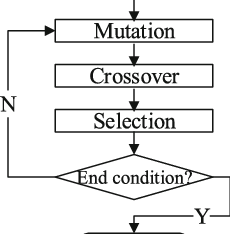

### 🤔 K čemu se hodí:
**Optimalizační Problémy:** Diferenciální evoluce exceluje v nalezení optimálních nebo téměř optimálních řešení pro širokou škálu optimalizačních problémů, jak kontinuálních, tak diskrétních.

**Komplexní Hledací Prostor:** Ideální pro problémy s komplexními, vysoce rozměrnými a nerovnoměrnými hledacími prostory, kde tradiční optimalizační metody, jako jsou gradientní metody, selhávají kvůli lokálním minimům nebo nepředvídatelným gradientům.

**Nelineární Problémy:** Vhodné pro nelineární problémy, kde vztahy mezi proměnnými nejsou přímočaré.

**Problémy s Nejasnými nebo Skrytými Vztahy:** Účinné pro problémy, kde není jasný nebo přesně definovaný vztah mezi vstupy a výstupy.

**Black-box Optimalizace:** Problémy, kde je cílová funkce "black-box", tedy kde nejsou známy její interní mechaniky, a jediná dostupná informace je výstup pro daný vstup.

**Nevyhovující Prostředí pro Derivace:** Problémy, kde nelze snadno vypočítat derivace nebo kde jsou derivace velmi nákladné na výpočet.

**Multi-modalní Funkce:** Problémy s více optimálními řešeními, kde je cílem najít jedno z mnoha optimálních řešení.

---

*Ve zkratce:* optimalizace (minimalizace/maximalizace) prakticky čehokoliv. Optimalizací obvykle myslíme to, že chceme nastavit parametry systému tak, abychom zoptimalizovali, myšleno minimalizovali/maximalizovali, jeho výstup. Typicky jde o snížení nákladů na výrobu, či třeba ideální množství dodávaného maziva do stroje.

### 👁️ Fitness funkce
- rozhoduje o tom jak moc je jedinec dobrý - **jak moc dobře odpovídá řešení**
- většinou vrací nějaké **skóre**
- toto **skóre** můžeme chtít maximalizovat nebo minimalizovat dle povahy problému
  - max: největší výnos
  - min: snižování nákladů

In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Knihovny Scipy pro práci s evolučními algorimy a dalšími nástroji Operačního výzkumu
import math
import random

## 📃 ČÁST 1: Demonstrace populace

In [ ]:
# Inicializace populace
def initialize_population(pop_size:int, bounds:list):
  population = np.random.rand(pop_size, len(bounds))
  population_denorm = bounds[:, 0] + population * (bounds[:, 1] - bounds[:, 0])
  return population, population_denorm

In [ ]:
# Velikost populace
population_size = 100
# Hranice prostoru - oblast v které je řešení
# Konkretně to může být: Výkon <od, do>, Cena  <od, do>
bounds = np.array([[-5, 5], [-5, 5]]) # 2D problém

# Vygenerování populace
# population - surově vygenerovaná populace
# population_denorm - populace škálovaná mezi hranicemi prostoru
population, population_denorm = initialize_population(population_size, bounds)

### 🧠 ÚKOL 1:
Prozkoumejte vygenerovanou populaci
- vypište si `shape` a prvních 5 záznamů
- vykreslete data pomocí 2D `Scatter` plotu





In [ ]:
# Tvar populace (shape)


In [ ]:
# Prvních 5 jedinců


In [ ]:
# Tvar denormalizované populace (shape)


In [ ]:
# Prvních 5 jedinců denormalizované populace


In [ ]:
# Scatter graf denormalizované populace


## ⭐ ČÁST 2: Příprava algoritmu (MODEL)

### Fitness funkce

In [ ]:
# Demostrační: chceme minimilizovat
# Vlastnosti: pouze kladné, min 0
def objective_function(x):
    return np.sum(x**2)

### Bez knihovny:

In [ ]:
# Zkopírujte diferenciální algoritmus z příklasu výše a zkuste jej upravit tak,
# aby pomocí funkce plot_evo(pop, best, gen_indx) vykresloval co generaci celou popluaci a aktuálně nejlepšího jedince.
"""
Implementace diferenciální evoluce pro optimalizaci dané funkce.

:param func: Cílová funkce k optimalizaci.
              Tato funkce by měla přijímat 1D pole jako vstup a vracet skalar.
:param bounds: Seznam nebo pole tuplů (min, max) pro každou proměnnou v funkci.
:param pop_size: Velikost populace (default 50).
                  Větší populace může zvýšit diverzitu, ale také zvyšuje výpočetní nároky.
:param F: Faktor mutace (default 0.8).
          Ovlivňuje rychlost a rozsah mutačních změn.
          Vyšší hodnoty zvyšují diverzitu, ale mohou způsobit nestabilitu.
:param CR: Pravděpodobnost rekombinace (default 0.7).
            Určuje, jak často jsou komponenty mutantních vektorů použity.
:param max_gen: Maximální počet generací (default 1000).
                Určuje, kdy algoritmus končí, pokud není nalezeno lepší řešení.

:return: Tuple (nejlepší nalezené řešení, hodnota fitness nejlepšího řešení)
"""
def differential_evolution(objective_function, bounds, pop_size=50, F=0.8, CR=0.7, max_gen=1000):
    # Inicializace populace
    population = np.random.rand(pop_size, len(bounds))
    # Fitness funkce pro každého jedince
    fitness = np.asarray([objective_function(ind) for ind in population])
    # inicialize nej jedince
    best_idx = np.argmin(fitness)
    best = population[best_idx]

    for i in range(max_gen):
      print(f"Gen: {i}")
      for j in range(pop_size):
          print(f"Pop: {j}")
          # Mutace
          idxs = [idx for idx in range(pop_size) if idx != j] # výběr náhodných indexů jedinců
          a, b, c = population[np.random.choice(idxs, 3, replace=False)] # výběr náhodných jedinců
          mutant = np.clip(a + F * (b - c), 0, 1) # vytvoření mutanta
          print(f"\t mutant:{mutant}")

          # Rekombinace - křížení
          cross_points = np.random.rand(len(bounds)) < CR # náhodně vybrané rekombinace
          if not np.any(cross_points):
              cross_points[np.random.randint(0, len(bounds))] = True # pokud se žádná náhodně nevygeneruje, nastaví se jedná náhodná
          trial = np.where(cross_points, mutant, population[j]) # křížení
          print(f"\t cross_points:{cross_points}, trial:{trial}")


          # Selekcí
          f = objective_function(trial) # skore finess fce pro nového jedince
          if f < fitness[j]: # pokud je lepší tak nový jedinec nahradí původního
              fitness[j] = f
              population[j] = trial
              if f < fitness[best_idx]: # kontrola zda je nejlepší
                  best_idx = j
                  best = trial
          print(f"\t best index:{best_idx}, best:{best}, value:{fitness[j]}")

    # denorm best solution
    best_denorm = [np.clip(best[d], bounds[d][0], bounds[d][1]) for d in range(len(bounds))] # denormalizace
    return best_denorm, fitness[best_idx] # vrátím nejlepšího jedince a nejlepší výsledek


### S knihovnou Scipy:

In [ ]:
# Příklad diferenciální evoluce
import scipy
result = scipy.optimize.differential_evolution(objective_function, bounds)

print("Optimal Solution:", result.x)
print("Objective Value:", result.fun)

Optimal Solution: [0. 0.]
Objective Value: 0.0


## ✅ ČÁST 3: Testovaní

In [ ]:
def objective_function(x):
    return np.sum(x**2)

In [ ]:
# Hranice prostoru
bounds = np.array([[-5, 5], [-5, 5]]) # 2D problém

# Příklad použití
solution, value = differential_evolution(objective_function, bounds, pop_size=10, max_gen=10)

print("Optimal Solution:", solution)
print("Objective Value:", value)

Gen: 0
Pop: 0
	 mutant:[0.39515961 0.68462506]
	 cross_points:[ True  True], trial:[0.39515961 0.68462506]
	 best index:9, best:[-0.22209425  1.3150622 ], value:4.507791995449867
Pop: 1
	 mutant:[0.84204441 0.26416517]
	 cross_points:[False  True], trial:[0.62113037 0.26416517]
	 best index:9, best:[-0.22209425  1.3150622 ], value:7.029063338235787
Pop: 2
	 mutant:[0.51037287 0.19262666]
	 cross_points:[ True  True], trial:[0.51037287 0.19262666]
	 best index:9, best:[-0.22209425  1.3150622 ], value:9.458596640046519
Pop: 3
	 mutant:[0.48108164 0.66352514]
	 cross_points:[ True  True], trial:[0.48108164 0.66352514]
	 best index:9, best:[-0.22209425  1.3150622 ], value:2.709837437965463
Pop: 4
	 mutant:[0.58520387 0.28016205]
	 cross_points:[ True  True], trial:[0.58520387 0.28016205]
	 best index:9, best:[-0.22209425  1.3150622 ], value:5.558842395181978
Pop: 5
	 mutant:[0.37239019 0.72740069]
	 cross_points:[False  True], trial:[0.40497249 0.72740069]
	 best index:9, best:[-0.22209425

### 🧠 ÚKOL 2:
Vykreslete graf (Scatter) populace před evolucí po evoluci
- eventuálně co generaci aby byl vidět rozdíl

In [ ]:
# Graf který vykreslí jednu populaci a jejího nejlepšího jedince
def plot_evo(pop, best, gen_indx):
  # pop[:,0] DIM 0 - X
  # pop[:,1] DIM 1- Y
  plt.scatter(pop[:,0], pop[:,1], marker="x", c="black")
  plt.scatter(best[0], best[1], marker="x", c="red")
  plt.title(f"{gen_indx}")
  plt.show()

In [ ]:
# Zkopírujte diferenciální algoritmus z příklasu výše a zkuste jej upravit tak,
# aby pomocí funkce plot_evo(pop, best, gen_indx) vykresloval co generaci celou popluaci a aktuálně nejlepšího jedince.



In [ ]:
# Hranice prostoru
bounds = np.array([[-5, 5], [-5, 5]]) # 2D problém

# Znovu spusť evoluci s vykreslováním grafu
solution, value = differential_evolution(objective_function, bounds, pop_size=10, max_gen=10)

print("Optimal Solution:", solution)
print("Objective Value:", value)

## 🍃 Problém: Optimalizace Energeticky Efektivního Návrhu Budovy
**Cíl:** Minimalizovat celkovou spotřebu energie budovy (náklady na energie).

**Proměnné:**

- *Tloušťka izolace:* Různé tloušťky izolačních materiálů mohou ovlivnit tepelné vlastnosti budovy.
  - hodnoty: 5, 10, 15, 20 cm
  - ceny: 10, 15, 20, 25 Kč
  - hodnota TI (tep. izolace (m²·K/W)): 1.4, 2.8, 4.2, 5.8
- *Typ okenního skla:* Různé typy skel (dvojité, trojité, s nízkým emisním povlakem) mají různé izolační vlastnosti.
  - hodnoty: 1,2,3
  - ceny: 100, 250, 400 Kč
  - hodnota TI (tep. izolace (m²·K/W)): 0.5, 1.8, 2.6

**Omezení:**

- *Rozpočet:* Celkové náklady na materiály a systémy musí být v rámci rozpočtu.
  - 10.000 až 300.000


**Fitness funkce:**
- Celkové náklady na konstrukci a údržbu (snažíme se ji minimalizovat).
  - vzorec: ((rozloha izolace * cena izolace) + (počet oken * cena oken) * (1/energetická efektivita))
  - Energentická efektivita: vypočtěte z hodnot TI


**Postup:**
- Vytvoření populace návrhů s různými kombinacemi proměnných.
- Použití diferenciální evoluce pro iterativní vylepšování návrhů na základě fitness funkce.
- Identifikace nejlepšího možného návrhu, který minimalizuje spotřebu energie a náklady, zatímco splňuje všechna omezení a požadavky.

### 🧠 ÚKOL 3:
Vyřešte pomocí DE následující problém.

In [ ]:
# Hranice prostoru a definice populace
# šířka polyst., typ oken, ve tvaru [[typ izolace], [typ skla]]

izolation_type=[???, ???] #doplň  ve tvaru [min, max]
window_type=[???, ???] #doplň ve tvaru [min, max]
bounds = np.array([izolation_type, window_type]) # 2D problém

# Parametry domu
# počet oken, rozloha - dáno konstantně
area = 100
n_windows = 5

# Ceny materiálu a jejich TI
# izolace a okna
izolation_cost_unit = {5:10, #doplň zbytek}
izolation_TI_unit = {5:1.4, #doplň zbytek}
window_cost_unit = {1:100, #doplň zbytek}
window_TI_unit = {1:0.5, #doplň zbytek}

#Omezeni
# rozpočet, ve tvaru [min, max]
constraint = [???, ???] #doplň

In [ ]:
def find_nearest(input_list, input_val):
    """
    Find the value in input_list closest to input_val.

    @param input_list: List of numerical values
    @param input_val: The value to compare against
    @return: The closest value from input_list
    """
    return min(input_list, key=lambda x: abs(x - input_val))

# Příklad fitness fce
# Zkuste ji dopsat a případně vylepšit
# x - jedinec z polulace, x[0] - typ izolace, x[1] typ skla
def price_eff(x):
  # cena izolace - příklad výpočtu
  izolation_type = int(x[0])
  izolation_type = find_nearest(izolation_cost_unit.keys(), izolation_type)
  izolation_cost = izolation_cost_unit[izolation_type] * area
  # cena oken
  window_type = ???
  window_type = ???
  windows_cost = ???

  #celkem = cena izolace a okoen
  total =  ???

  #Omezeni
  # zde přidat hlídaní omenzeni total ceny vůči constraint (10000 < total < 300000)
  # použijte if/else

  return total

# Zkus navrhnout vzorec pro výpočet energetické efektivity na základě druhu izolace
def energy_eff(x):
  izolation_type = int(x[0])
  isolation_type = find_nearest(izolation_TI_unit.keys(), izolation_type)
  isolation_TI = izolation_TI_unit[isolation_type]

  windows_type = ???
  windows_type = ???
  windows_TI = ???
  # defaultně můžeme v rámci testů prozatím nechat 0.8,
  # ale aby cost fce fungovala dobře, měl by zde být vztah mezi použitým zateplením a efektivetě
  return 0.8

# Vaše základní cost funkce
def building_eff(x):
  return ??? * (1.0 / ???) # doplň dle zadání

In [ ]:
# Hranice prostoru pro hledání řešení
bounds

array([[ 5, 20],
       [ 1,  3]])

In [ ]:
# One-shot test fitness funkce
x = np.array([10, 1]) # izolace 10cm, jednovrstvé okno
print(price_eff(x))
print(energy_eff(x))
print(building_eff(x))

In [ ]:
# Použijte genetický algoritmus a vyřešte problém Optimalizace Energeticky Efektivního Návrhu Budovy
# Dejte pozor co je fitness funkce, co je populace a kolik použít generací a jak velkou populaci vygenerovat
solution, value = differential_evolution(???, ???, pop_size=??, max_gen=??)

print("Optimal Solution:", solution)
print("Objective Value:", value)